# Notebook 17: Compact Observation Comparison

This experiment tests whether a small amount of project and income-history information improves mixed-scenario tabular Q-learning. The current eight-feature observation is compared with two compact additions. Rewards, environmental and economic equations, training budgets, seeds, and evaluation conditions stay fixed.

The project-status variant adds one four-level feature: no projects, active projects, pending projects, or both. The timing variant adds one six-level category for the nearest activation or expiry event, plus a three-level income trend (falling, stable, rising). The added features are derived from existing environment records and do not change state transitions.

Each variant trains local, global, and mixed rewards for 300, 1,000, and 3,000 episodes with seeds 11, 23, and 37. Episodes sample low, reference, and high pollution settings. Every checkpoint is evaluated separately under all three conditions.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from study_3_pollutant_dynamics.observation_comparison import run_observation_comparison
from study_3_pollutant_dynamics.policy_evaluation import run_fixed_policy_episode
from study_3_pollutant_dynamics.rl_experiments import _make_environment, summarize_episode_metrics

In [4]:
RESULTS_DIRECTORY = "../results/rl_observation_comparison"
RUN_EXPERIMENT = False

## Run or load the matched experiment

Training is the slowest cell. Set `RUN_EXPERIMENT` to `False` after results have been saved to reload the CSV files. Q-table checkpoints and episode-level training history are saved with the evaluation results.

In [5]:
if RUN_EXPERIMENT:
    training_rows, evaluation_rows, action_rows = run_observation_comparison(RESULTS_DIRECTORY)
    training = pd.DataFrame(training_rows)
    evaluation = pd.DataFrame(evaluation_rows)
    actions = pd.DataFrame(action_rows)
else:
    training = pd.read_csv(RESULTS_DIRECTORY + "/training_history.csv")
    evaluation = pd.read_csv(RESULTS_DIRECTORY + "/evaluation.csv")
    actions = pd.read_csv(RESULTS_DIRECTORY + "/action_frequencies.csv")

print("Training records:", len(training))
print("Evaluation records:", len(evaluation))
print("Action records:", len(actions))

Training records: 81000
Evaluation records: 243
Action records: 7776


## Performance and state coverage

Compare the policy outcomes across observation variants at each training duration. Unseen-state frequency is measured across all region-year observations in the evaluation episode. A larger Q-table is useful only if its added states support better decisions.

In [6]:
comparison_columns = ["final_mean_EDI", "cumulative_net_income", "mitigation_spending",
                      "unseen_state_visit_fraction", "unique_training_states",
                      "mean_CO2_ppm", "mean_PM2.5_ug_m3", "mean_nitrate_mg_N_L",
                      "mean_lead_total_kg"]
comparison = evaluation.groupby(["observation_variant", "reward_mode", "training_episodes",
                                 "evaluation_scenario"], sort=False)[comparison_columns].mean().reset_index()
display(comparison.round(3))

,observation_variant,reward_mode,training_episodes,evaluation_scenario,final_mean_EDI,cumulative_net_income,mitigation_spending,unseen_state_visit_fraction,unique_training_states,mean_CO2_ppm,mean_PM2.5_ug_m3,mean_nitrate_mg_N_L,mean_lead_total_kg
0,current,local,300,low,95.500,18570.220,3106.667,0.075,337.000,466.057,8.565,1.919,8.529
1,current,local,300,reference,95.167,17348.050,2800.000,0.115,337.000,477.558,8.572,2.433,13.376
2,current,local,300,high,95.667,13507.919,2620.000,0.102,337.000,503.438,8.616,2.945,35.949
3,current,local,1000,low,96.917,18636.023,3486.667,0.023,413.667,466.101,8.565,1.920,8.483
4,current,local,1000,reference,97.250,17480.546,3166.667,0.021,413.667,477.571,8.572,2.421,13.305
...,...,...,...,...,...,...,...,...,...,...,...,...,...
76,project_timing_income,mixed,1000,reference,97.167,17439.215,3400.000,0.023,1206.667,477.379,8.568,2.378,13.363
77,project_timing_income,mixed,1000,high,96.750,13847.788,3366.667,0.023,1206.667,503.309,8.597,2.861,35.527
78,project_timing_income,mixed,3000,low,97.917,18590.929,3826.667,0.000,1416.333,465.919,8.564,1.889,8.622
79,project_timing_income,mixed,3000,reference,98.333,17418.690,3526.667,0.000,1416.333,477.383,8.568,2.379,13.354


In [7]:
latest = comparison[comparison["training_episodes"] == 3000]
for metric in ("final_mean_EDI", "unseen_state_visit_fraction", "unique_training_states"):
    pivot = latest.pivot_table(index=["reward_mode", "evaluation_scenario"],
                              columns="observation_variant", values=metric)
    print(metric)
    display(pivot.round(3))

final_mean_EDI


observation_variant              current  project_status  \
reward_mode evaluation_scenario                            
global      high                  96.333          95.750   
            low                   95.667          96.500   
            reference             96.417          96.000   
local       high                  98.083          97.667   
            low                   97.500          97.333   
            reference             98.000          98.000   
mixed       high                  98.083          97.083   
            low                   97.583          97.500   
            reference             98.083          98.000   

observation_variant              project_timing_income  
reward_mode evaluation_scenario                         
global      high                                94.750  
            low                                 96.333  
            reference                           95.750  
local       high                                97.083  
            low                                 98.500  
            reference                           98.000  
mixed       high                                97.500  
            low                                 97.917  
            reference                           98.333

unseen_state_visit_fraction


observation_variant              current  project_status  \
reward_mode evaluation_scenario                            
global      high                     0.0             0.0   
            low                      0.0             0.0   
            reference                0.0             0.0   
local       high                     0.0             0.0   
            low                      0.0             0.0   
            reference                0.0             0.0   
mixed       high                     0.0             0.0   
            low                      0.0             0.0   
            reference                0.0             0.0   

observation_variant              project_timing_income  
reward_mode evaluation_scenario                         
global      high                                   0.0  
            low                                    0.0  
            reference                              0.0  
local       high                                   0.0  
            low                                    0.0  
            reference                              0.0  
mixed       high                                   0.0  
            low                                    0.0  
            reference                              0.0

unique_training_states


observation_variant              current  project_status  \
reward_mode evaluation_scenario                            
global      high                 440.000         930.333   
            low                  440.000         930.333   
            reference            440.000         930.333   
local       high                 453.000         971.667   
            low                  453.000         971.667   
            reference            453.000         971.667   
mixed       high                 452.667         964.333   
            low                  452.667         964.333   
            reference            452.667         964.333   

observation_variant              project_timing_income  
reward_mode evaluation_scenario                         
global      high                              1320.333  
            low                               1320.333  
            reference                         1320.333  
local       high                              1413.000  
            low                               1413.000  
            reference                         1413.000  
mixed       high                              1416.333  
            low                               1416.333  
            reference                         1416.333

## Training duration and action choices

This view checks whether the richer representations gain or lose ground as the training budget increases. Action frequencies help distinguish a coverage improvement from a policy that simply defaults to a different action.

In [8]:
duration_summary = comparison.groupby(["observation_variant", "training_episodes"])[
    ["final_mean_EDI", "unseen_state_visit_fraction", "unique_training_states"]].mean().reset_index()
display(duration_summary.round(3))

,observation_variant,training_episodes,final_mean_EDI,unseen_state_visit_fraction,unique_training_states
0,current,300,95.009,0.090,336.000
1,current,1000,96.620,0.012,411.111
2,current,3000,97.306,0.000,448.556
3,project_status,300,93.361,0.173,679.111
4,project_status,1000,96.046,0.029,865.000
5,project_status,3000,97.093,0.000,955.444
6,project_timing_income,300,92.704,0.185,826.778
7,project_timing_income,1000,96.435,0.022,1193.778
8,project_timing_income,3000,97.130,0.000,1383.222


In [9]:
action_summary = actions[actions["training_episodes"] == 3000].groupby(
    ["observation_variant", "action"], sort=False)["fraction"].mean().unstack(fill_value=0)

display(action_summary.round(3))

action,maintain,develop,prevention,develop_prevention,cleanup,develop_cleanup,balanced,develop_balanced
observation_variant,,,,,,,,
current,0.030,0.217,0.021,0.229,0.017,0.243,0.021,0.223
project_status,0.039,0.248,0.023,0.233,0.019,0.207,0.021,0.209
project_timing_income,0.035,0.225,0.025,0.234,0.013,0.225,0.021,0.221


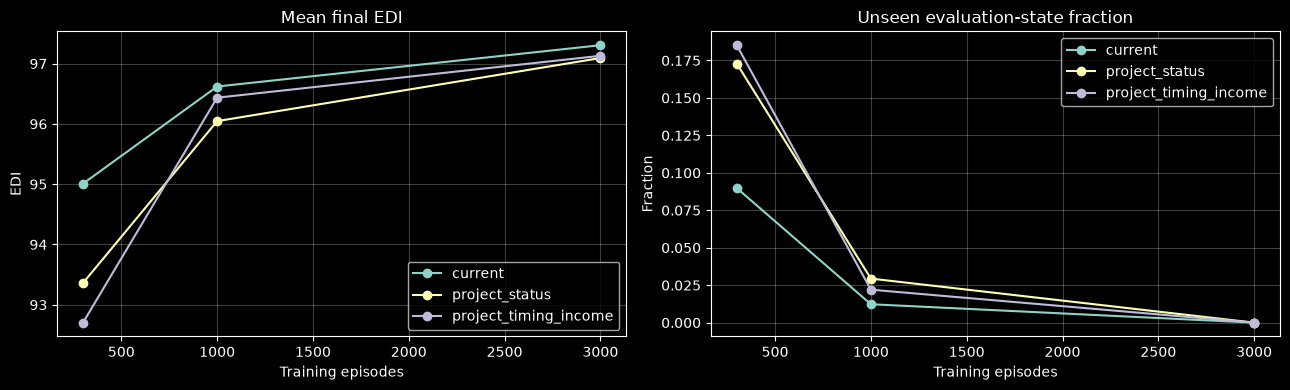

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for variant, group in duration_summary.groupby("observation_variant", sort=False):
    axes[0].plot(group["training_episodes"], group["final_mean_EDI"], marker="o", label=variant)
    axes[1].plot(group["training_episodes"], group["unseen_state_visit_fraction"], marker="o", label=variant)
axes[0].set(title="Mean final EDI", xlabel="Training episodes", ylabel="EDI")
axes[1].set(title="Unseen evaluation-state fraction", xlabel="Training episodes", ylabel="Fraction")
for axis in axes:
    axis.legend()
    axis.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## Balanced fixed-policy reference

The balanced rule is included as a practical benchmark. The comparison should consider whether richer Q-learning observations improve on the current representation and how both compare with a policy that does not learn.

In [11]:
fixed_rows = []
for scenario in ("low", "reference", "high"):
    config, environment = _make_environment(scenario, 40, 1.0, 0.6, "constant")
    trajectory, terminated, truncated = run_fixed_policy_episode("balanced", environment, 0)
    row = summarize_episode_metrics(trajectory, environment)
    row["evaluation_scenario"] = scenario
    fixed_rows.append(row)

fixed_baseline = pd.DataFrame(fixed_rows)
display(fixed_baseline[["evaluation_scenario", "final_mean_EDI", "cumulative_net_income", "development_spending",
                        "mitigation_spending", "final_CO2_ppm", "final_mean_PM2.5_ug_m3",
                        "final_mean_nitrate_mg_N_L", "final_mean_lead_total_kg"]].round(3))

,evaluation_scenario,final_mean_EDI,cumulative_net_income,development_spending,mitigation_spending,final_CO2_ppm,final_mean_PM2.5_ug_m3,final_mean_nitrate_mg_N_L,final_mean_lead_total_kg
0,low,98.75,18843.584,3375.0,6400.0,504.210,8.565,1.946,6.339
1,reference,98.75,18216.615,3375.0,6400.0,526.610,8.570,2.445,11.707
2,high,98.75,16934.699,3375.0,6400.0,577.038,8.596,2.917,47.757


## Reading the comparison

Use the cross-scenario outcomes alongside EDI, income, spending, and pollutant measures. Lower unseen-state rates alone do not establish better decisions. If additional features increase Q-table size while performance stays flat or declines, the result indicates a state-sparsity cost for tabular Q-learning.

The experiment uses three training seeds and a deterministic environment. Seeds vary exploration and learned tables; they are not independent environmental realizations. The results support a decision about the tabular representation, not real-world environmental claims.

## Result summary

At 3,000 episodes, the current observation averages 97.31 final EDI across reward modes and evaluation conditions (seed SD 0.96). Project status averages 97.09 (SD 0.88), and project timing with income trend averages 97.13 (SD 1.28). All three variants have zero unseen-state visits in these evaluations.

The added features increase the mean number of learned region states from about 449 to 955 and 1,383. At 300 episodes, richer variants have lower mean EDI (93.36 and 92.70) than the current encoding (95.01), and higher unseen-state fractions (17% and 19%, versus 9%). By 3,000 episodes, performance is similar, not better.

At 3,000 episodes, mean mitigation spending is about 3,423 under the current encoding, 3,760 with project status, and 3,673 with timing and income trend. Pollutant differences are small and mixed across scenarios. The balanced fixed policy reaches mean EDI 98.75 in each condition and spends 6,400 on mitigation. These results do not show a practical gain from the extra observation features.